# 02 - Candidate `.h5` Anatomy

nb01 stayed on metadata. This one goes inside: the two (256, 256) arrays sitting in each of the 102 `.h5` candidates, what their axes actually
mean, and which 1-D curves we'll be pulling the nb04 features off.

**Inputs**
`frb_analysis_out/nb01/candidates_labelled.csv` and the 102 `.h5` files. The `.fil` is for nb03.

**Goals for this Notebook**
1. Calibrate both axes of `data_dm_time` and `data_freq_time`. Neither one is written down anywhere.
2. Work out whether `SNR(DM=0)/SNR(DM_peak)` is even computable. This decides whether the main Group C feature exists at all.
3. Pin down the collapse convention for the 1-D curves. If this is wrong we will get a flat line and no error message.
4. Measure the `std == 1` problem, since nb01 only stated it.
5. Have a proper look at positives against negatives, and at the injection FETCH binned.

In [1]:
import sys
from pathlib import Path
CODE_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "frb_eda").is_dir())
sys.path.insert(0, str(CODE_ROOT))

import json
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis

from frb_eda import axes as h5axes, config, parallel, raw
from frb_eda.physics import dm_delay_s

NB01_DIR = config.OUT_ROOT / "nb01"
NB02_DIR = config.out_dir("nb02")

cands = pd.read_csv(NB01_DIR / "candidates_labelled.csv")

# Guards: nb02 is meaningless if the master table isn't what nb01 left behind.
assert cands["h5_name"].is_unique, "duplicate candidates in the master table"
assert {"chunk_nstart", "chunk_nsamp"} <= set(cands.columns), "rerun nb01: chunk geometry missing"
cands["h5_path"] = [str(config.CAND_DIR / n) for n in cands["h5_name"]]   # never trust a stored absolute path
missing = [p for p in cands["h5_path"] if not Path(p).exists()]
assert not missing, f"{len(missing)} .h5 files missing, first: {missing[:1]}"

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

print(f"{len(cands)} candidates | {cands['is_injection'].sum()} injections "
      f"| {(~cands['is_injection']).sum()} negatives")
print(f"outputs -> {NB02_DIR}")

102 candidates | 13 injections | 89 negatives
outputs -> C:\Users\Hans\OneDrive\Documents\QML\FRB Data\frb_analysis_out\nb02


## What's inside one file

### Why
Pretty much everything below rests on the shape, dtype and dimension labels of two arrays, so let's dump one file in full, once, before the next twenty cells build on it.

### What we're looking at
| thing | meaning |
|---|---|
| `data_freq_time` | (256, 256) float32, dims `['time', 'frequency']`: the dedispersed waterfall |
| `data_dm_time` | (256, 256) float32, dims `['dm', 'time']`: the DM-vs-time "bowtie" |
| attrs | 20-odd scalars copied off the header, plus the candidate parameters |

### The bit that caught me 
**The two arrays are transposed relative to each other.** `freq_time` is time-major, `dm_time` is dm-major. Collapsing the wrong axis gives you a curve that looks completely reasonable and means nothing, and nothing raises.

### Stale Attrs
nb01 caught `label` (0 everywhere) and the two `*_decimation_factor` attrs (both claim 1, the log says freq=4 and time=1..512). Two more turned up while poking at this:

| attr | value | what it really is |
|---|---|---|
| `nspectra` | `1012964` on all 102 | that's the **whole file's** sample count, not the cutout |
| `dm_opt`, `snr_opt` | `-1` on all 102 | sentinel. The log confirms `opt_dm: False` |

That's four separate attr families in this file that are placeholders.

In [2]:
def dump_h5(path, max_attr_len=60):
    """Print the full tree + attrs of one .h5. Read-only, no side effects."""
    def show(name, obj):
        kind = "DSET" if isinstance(obj, h5py.Dataset) else "GRP "
        extra = f" shape={obj.shape} dtype={obj.dtype}" if isinstance(obj, h5py.Dataset) else ""
        print(f"  {kind} /{name}{extra}")
        for k, v in obj.attrs.items():
            s = str(v)
            print(f"        @{k} = {s[:max_attr_len]}")

    with h5py.File(path, "r") as f:
        print(f"FILE {Path(path).name}\n")
        print("  root attrs:")
        for k, v in sorted(f.attrs.items()):
            s = str(v)
            print(f"        @{k} = {s[:max_attr_len]}")
        print("\n  tree:")
        f.visititems(show)


ref = cands[cands["is_injection"]].nlargest(1, "snr_csv").iloc[0]
print(f"reference candidate: DM {ref.dm_csv:.2f}, S/N {ref.snr_csv:.2f}, "
      f"tcand {ref.tcand:.4f} s\n")
dump_h5(ref.h5_path)

reference candidate: DM 530.37, S/N 50.52, tcand 70.0157 s

FILE cand_tstart_60356.799484982548_tcand_70.0157000_dm_530.37100_snr_50.51560.h5

  root attrs:
        @basename = CUT_P_110_inj_13_processed
        @bw = -14.814814814814813
        @cand_id = cand_tstart_60356.799484982548_tcand_70.0157000_dm_530.37100
        @center_freq = 408.45428240740745
        @dec_deg = 45.27611111111111
        @dm = 530.371
        @dm_opt = -1
        @dtype = uint16
        @fch1 = 415.85445601851853
        @filelist = ['/jbod/GEM/TEST_HF/INJECTED/CUT_P_110_inj_13_processed.fil'
        @filename = /jbod/GEM/TEST_HF/INJECTED/CUT_P_110_inj_13_processed.fil
        @foff = -0.014467592592592591
        @format = fil
        @frequency_decimation_factor = 1
        @gb = 1.9490338837641128
        @gl = -18.453250034405244
        @kill_mask = [False]
        @label = 0
        @native_foff = -0.014467592592592591
        @native_nbits = 16
        @native_nchans = 1024
        @native_nspectra

## Axis calibration

### Why
This is the main thing for this notebook. Neither array carries any axis coordinates: no `dm_list`, no time array, no start offset. nb01 flagged it, and `nspectra` turning out to be stale killed a shortcut I was hoping to use.

The files came out of `your`'s `your_candmaker.py`. The log shows this run used the GPU path, `gpu_dedisp_and_dmt_crop` in `your/utils/gpu.py`, so that's the code the axes have to come from, together with `Candidate.get_chunk` in `your/candidate.py`.

### The DM axis of `data_dm_time`

    dm_list = np.linspace(0, 2 * cand.dm, 256)

so:

| row | trial DM |
|---|---|
| 0 | **exactly 0** |
| 127.5 | the candidate DM (where the peak should sit) |
| 255 | `2 * dm` |

**DM = 0 is in the image**, which settles the Group C question: `SNR(DM=0)/SNR(DM_peak)` is computable for all 102, and it gets computed a few cells down.

How not to check this:

The peak sitting at row ~128 does not confirm the range. `dm +/- dm` and `dm +/- dm/2` are both centred there, so peak position only tells you the axis is symmetric. The scale needs a separate argument. nb03 §5 supplies it from the raw file.

### The time axis of both arrays

Three steps, and the first version of this notebook only had the first one.

1. **Read a chunk.** `get_chunk` asks for `tcand +/- (dispersion_delay(dm) + width*tsamp)`. If that is shorter than `width * 256 / 2` samples (256 when `width < 3`) it widens the read symmetrically to that length. nb01 checked this against the `nstart_read` / `nsamp_read` line the log writes for each candidate, and it matches on all 102.
2. **Dedisperse and decimate.** The GPU kernel shifts every channel to the top of the band and sums it into time bins of `max(1, width // 2)` samples and frequency bins of 4 channels.
3. **Crop.** It keeps the centre 256 time bins, starting at `int(n_bins / 2) - 128`.

So one column is `max(1, width // 2) * tsamp`, and the image spans 256 of those. `width` is the boxcar in **samples** (the h5 `width` attr, `boxcar_samples` in the master table), not the log2 version from `all_candidates.csv`. nb01 flagged these two.

What I first wrote here was step 1 followed by "resize to 256 columns", i.e. a window of `2 * (sweep + width*tsamp)` stretched over 256 columns. That model also centres the pulse on `tcand`, so the peak check below can't tell the two apart. nb03 §5 can: it rebuilds the h5 profile from raw counts under both models, and only the decimate-then-crop one matches.

### The consequence
The window scales with the **boxcar**, not with DM. A boxcar-1 candidate spans 35 ms whatever its DM, a boxcar-1024 one spans 18.1 s, and a pulse covers about two columns in every image by design. candmaker is width-normalising the image for FETCH. Two things follow for nb04:

- A feature measured in columns is measured in units of the candidate's own boxcar. Converting it to milliseconds multiplies in `boxcar_samples`.
- The h5 image can't measure pulse width. Every pulse is ~2 columns wide by construction, so width has to come from the raw file.

In [3]:
# Instrument constants, from the raw header (nb01, verified).
FCH1  = 415.85445601851853     # channel 0 centre, MHz
FOFF  = -0.014467592592592591  # channel spacing, MHz (negative -> band descends)
NCHAN = 1024
TSAMP = 138.24e-6              # s
F_HI  = FCH1
F_LO  = FCH1 + FOFF * (NCHAN - 1)
NDM = NTIME = 256


def dm_axis(dm, n=NDM):
    """Trial DMs for the rows of data_dm_time. Row 0 is exactly DM 0."""
    return h5axes.h5_dm_axis(dm, n)


def time_axis_ms(row):
    """Column centres of both arrays, ms relative to tcand, from the exact chunk
    candmaker read (frb_eda.axes.h5_time_axis_exact)."""
    return h5axes.h5_time_axis_exact(row.tcand, row.dm_csv, int(row.boxcar_samples),
                                     TSAMP, F_HI, F_LO) * 1e3


def freq_axis(n=NDM):
    """Decimated channel centres, MHz. Index 0 is the TOP of the band."""
    return h5axes.freq_axis(F_HI, F_LO, n)


print(f"band {F_LO:.6f} - {F_HI:.6f} MHz")
print(f"dispersion delay = {float(dm_delay_s(1.0, F_HI, F_LO))*1e3:.6f} ms per unit DM\n")

# the chunk model must reproduce what nb01 matched against the log
geo = np.array([h5axes.chunk_geometry(r.tcand, r.dm_csv, int(r.boxcar_samples), TSAMP, F_HI, F_LO)
                for r in cands.itertuples()])
assert (geo[:, 0] == cands.chunk_nstart).all() and (geo[:, 1] == cands.chunk_nsamp).all()
print("chunk geometry agrees with nb01's log match on all", len(cands))

demo = cands[cands["is_injection"]].sort_values("dm_csv").iloc[[0, 6, -1]]
print(f"\n{'DM':>9} {'W_samp':>7} {'decim':>6} {'window_ms':>10} {'ms/col':>8} {'DM/row':>8}")
for _, r in demo.iterrows():
    t = time_axis_ms(r)
    d = dm_axis(r.dm_csv)
    print(f"{r.dm_csv:9.2f} {r.boxcar_samples:7.0f} {int(h5axes.time_decimation(r.boxcar_samples)):6d} "
          f"{(t[-1] - t[0] + t[1] - t[0]):10.1f} {t[1]-t[0]:8.3f} {d[1]-d[0]:8.3f}")

band 401.054109 - 415.854456 MHz
dispersion delay = 1.803350 ms per unit DM

chunk geometry agrees with nb01's log match on all 102

       DM  W_samp  decim  window_ms   ms/col   DM/row
    46.18      16      8      283.1    1.106    0.362
   313.73    1024    512    18119.4   70.779    2.461
  2795.34     256    128     4529.8   17.695   21.924


## Does any of that survive contact with the data?

### Why?
Everything above came from reading someone else's source plus the log, which is good evidence but not proof. Two cheap predictions test the parts nb02 can test without the raw file.

### The two checks
| check | what should happen if the calibration is right |
|---|---|
| **DM peak row** | the DM-SNR curve peaks near row 127.5, the candidate DM |
| **Profile peak time** | the pulse sits within about a column of t = 0, i.e. of `tcand`'s column, which is not always the image centre |

Neither check pins the **scale** of an axis. Both candidate time models put the pulse in the middle of the image, and a wrong DM range would still peak at the middle row. The scale test is nb03 §5, which compares the h5 images with profiles rebuilt from raw counts.

### Guards
Most negatives have no dispersed signal at all, so their "peak row" is just wherever the noise happened to be loudest. Both checks are reported on the 13 injections for that reason: running them on noise gives a uniform scatter, which is the right answer.

In [4]:
def dm_snr_curve(dm_time):
    """DM-SNR curve: peak response at each trial DM, baseline removed.

    NOTE the max, not mean - see the collapse-convention cell below.
    """
    c = dm_time.max(axis=1).astype(float)
    return c - np.median(c)


def integrated_profile(freq_time):
    """Integrated profile: collapse data_freq_time over FREQUENCY (dims are
    ['time', 'frequency'], so that is axis=1)."""
    return freq_time.mean(axis=1).astype(float)


rows = []
for _, r in cands.iterrows():
    with h5py.File(r.h5_path, "r") as f:
        ft = f["data_freq_time"][:]
        dt = f["data_dm_time"][:]

    curve = dm_snr_curve(dt)
    prof  = integrated_profile(ft)
    t_ms  = time_axis_ms(r)
    td    = int(h5axes.time_decimation(r.boxcar_samples))

    rows.append({
        "h5_name":       r.h5_name,
        "is_injection":  r.is_injection,
        "dm_csv":        r.dm_csv,
        "snr_csv":       r.snr_csv,
        "boxcar_samples": r.boxcar_samples,
        "boxcar_ms":     r.boxcar_ms,
        "time_decim":    td,
        "h5_t_step_ms":  td * TSAMP * 1e3,
        "h5_window_ms":  NTIME * td * TSAMP * 1e3,
        "h5_t0_ms":      float(t_ms[0]),                 # centre of column 0, relative to tcand
        "raw_half_window_ms": (float(dm_delay_s(r.dm_csv, F_HI, F_LO)) + r.boxcar_samples * TSAMP) * 1e3,
        "dm_step":       float(2 * r.dm_csv / (NDM - 1)),
        "dm_peak_row":   int(curve.argmax()),
        "dm_peak_value": float(curve.max()),
        "tcand_col":     float(-t_ms[0] / (td * TSAMP * 1e3)),      # fractional column where t = 0
        "prof_peak_col_off": float(prof.argmax() - (NTIME - 1) / 2),  # from the image centre
        "prof_peak_off_tcand_col": float(prof.argmax() + t_ms[0] / (td * TSAMP * 1e3)),  # from tcand
        "prof_peak_ms":  float(t_ms[prof.argmax()]),
        "dm0_ratio":     float(curve[0] / curve.max()),
    })

axes = pd.DataFrame(rows)
pos = axes[axes["is_injection"]]

print("--- check 1: DM peak row (expect ~127.5) ---")
print(f"  injections: min {pos.dm_peak_row.min()}, median "
      f"{pos.dm_peak_row.median():.0f}, max {pos.dm_peak_row.max()}")

print("\n--- check 2: profile peak position (expect within ~1 column of t = 0) ---")
col_off = pos.prof_peak_ms / pos.h5_t_step_ms
print(f"  |offset| in columns: median {col_off.abs().median():.2f}, max {col_off.abs().max():.2f}")
shift = (axes.tcand_col - (NTIME - 1) / 2).abs()
print(f"  windows span {pos.h5_window_ms.min():.0f} - {pos.h5_window_ms.max():.0f} ms")
print(f"  tcand sits off the image centre by up to {shift.max():.2f} columns (median {shift.median():.2f}): "
      f"candmaker's integer chunk and crop arithmetic, which matters most when a column is only a few samples")
print(shift.groupby(axes.time_decim).median().round(2).rename("median |tcand - centre| in columns, by time_decim").to_frame().T.to_string())
print()

print(pos[["dm_csv", "snr_csv", "boxcar_samples", "h5_t_step_ms", "h5_window_ms", "dm_peak_row",
           "prof_peak_col_off", "prof_peak_off_tcand_col", "prof_peak_ms"]]
      .sort_values("dm_csv").to_string(index=False, float_format=lambda x: f"{x:.2f}"))

--- check 1: DM peak row (expect ~127.5) ---
  injections: min 125, median 128, max 138

--- check 2: profile peak position (expect within ~1 column of t = 0) ---
  |offset| in columns: median 0.45, max 1.29
  windows span 142 - 18119 ms
  tcand sits off the image centre by up to 2.24 columns (median 0.01): candmaker's integer chunk and crop arithmetic, which matters most when a column is only a few samples
time_decim                                          1     2     4     8     16    32    64    128  256  512
median |tcand - centre| in columns, by time_decim  1.38  1.25  0.97  0.31  0.09  0.04  0.02  0.01  0.0  0.0

 dm_csv  snr_csv  boxcar_samples  h5_t_step_ms  h5_window_ms  dm_peak_row  prof_peak_col_off  prof_peak_off_tcand_col  prof_peak_ms
  46.18    39.76              16          1.11        283.12          129               0.50                     0.32          0.36
  46.92    23.76              32          2.21        566.23          131               0.50                

## The DM = 0 feature

### Why 
Row 0 of `data_dm_time` is the data dedispersed to **DM 0** i.e. not corrected at all. 
So, that gives us a clean physical discriminator:

- A **dispersed** pulse, undone at DM 0, smears out across the full band sweep and its peak drops into the noise. Ratio near 0.
- **Broadband RFI** hits every frequency at once, so it's already "dedispersed" at DM 0 and looks just as good there as anywhere else. Ratio near 1.

So the feature is asking "does this thing care about dispersion at all?", which is pretty close to the physical definition of classification. That's the reason to know whether row 0 was really DM 0 before building on it.

### Guards
The ratio is taken on the baseline-subtracted curve, so a candidate with no signal anywhere gives noise-over-noise, which can land anywhere in [-1, 1]. That's why the negatives
spread out instead of piling up at 1. That's correct behaviour, but it does mean the feature is noisy on weak candidates.

### Expectations
Unlike every metadata feature in nb01, this one isn't degenerate on this observation. I'd argue that makes it more useful than an AUC of 1.000. `snr_csv` scoring a perfect 1.000 is a symptom of 13 loud injections in one clean file and says nothing about the encoding. A feature that lands somewhere in the middle is being tested.

SNR(DM=0) / SNR(DM_peak)
  injections (n= 13): median -0.009  IQR [-0.041, +0.042]  max +0.549
  negatives  (n= 89): median +0.307  IQR [+0.013, +0.532]  max +1.000

  AUC = 0.697


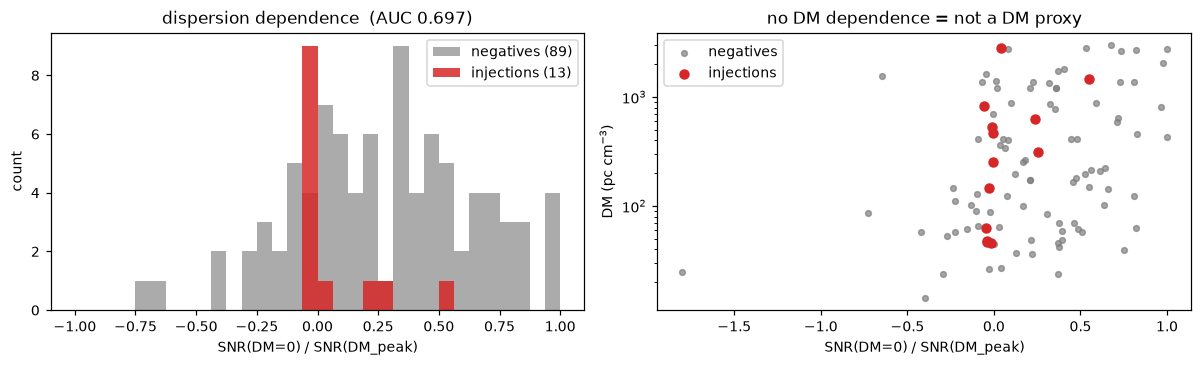

In [5]:
from sklearn.metrics import roc_auc_score

p = axes[axes["is_injection"]]["dm0_ratio"]
n = axes[~axes["is_injection"]]["dm0_ratio"]

# Lower ratio = more dispersion-like = more injection-like, hence the negation.
auc = roc_auc_score(axes["is_injection"], -axes["dm0_ratio"])

print("SNR(DM=0) / SNR(DM_peak)")
print(f"  injections (n={len(p):3d}): median {p.median():+.3f}  "
      f"IQR [{p.quantile(.25):+.3f}, {p.quantile(.75):+.3f}]  max {p.max():+.3f}")
print(f"  negatives  (n={len(n):3d}): median {n.median():+.3f}  "
      f"IQR [{n.quantile(.25):+.3f}, {n.quantile(.75):+.3f}]  max {n.max():+.3f}")
print(f"\n  AUC = {auc:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
bins = np.linspace(-1, 1, 33)
ax[0].hist(n, bins=bins, alpha=.65, label=f"negatives ({len(n)})", color="tab:grey")
ax[0].hist(p, bins=bins, alpha=.85, label=f"injections ({len(p)})", color="tab:red")
ax[0].set_xlabel("SNR(DM=0) / SNR(DM_peak)"); ax[0].set_ylabel("count")
ax[0].set_title(f"dispersion dependence  (AUC {auc:.3f})"); ax[0].legend()

ax[1].scatter(n, axes[~axes["is_injection"]]["dm_csv"], s=14, c="tab:grey",
              alpha=.7, label="negatives")
ax[1].scatter(p, axes[axes["is_injection"]]["dm_csv"], s=34, c="tab:red",
              label="injections")
ax[1].set_xlabel("SNR(DM=0) / SNR(DM_peak)"); ax[1].set_ylabel("DM (pc cm$^{-3}$)")
ax[1].set_yscale("log"); ax[1].set_title("no DM dependence = not a DM proxy"); ax[1].legend()
plt.tight_layout(); plt.savefig(NB02_DIR / "dm0_ratio.png", bbox_inches="tight"); plt.show()

## Collapse conventions

### Why?
The canonical 8 features are stats of two 1-D curves. Which axis you collapse and which operator you use is four separate decisions and none of them raise when you get them
wrong, which is how I lost an afternoon.

| curve | array | collapse over | operator |
|---|---|---|---|
| integrated profile | `data_freq_time` dims `['time','frequency']` | frequency -> `axis=1` | **mean** |
| DM-SNR curve | `data_dm_time` dims `['dm','time']` | time -> `axis=1` | **max** |

### The one that bit me
candmaker normalises each image to std exactly 1.0, and that normalisation is global, so every row of `data_dm_time` ends up carrying nearly the same total. Take the mean
along time and you get a flat line: the signal is a handful of bright samples in a row of 256 and averaging just buries it.

Take the max and the bowtie shows up. On the reference candidate:

    mean-collapse   peak-to-peak =  0.15
    max-collapse    peak-to-peak = 34.36        ~226x

For what it's worth the physical reading agrees with the working one... the DM-SNR curve is peak response versus trial DM, so `max` is the definition. The profile is the
opposite case, where `mean` is right because collapsing frequency is an average over channels.

data_dm_time collapsed over time, candidate DM 530.37
  mean : ptp   0.1520   peak at DM   844.43
  max  : ptp  34.3561   peak at DM   528.29
  ratio: 226x

  wrong axis (max over DM) -> length 256, that's a time series, not a DM curve


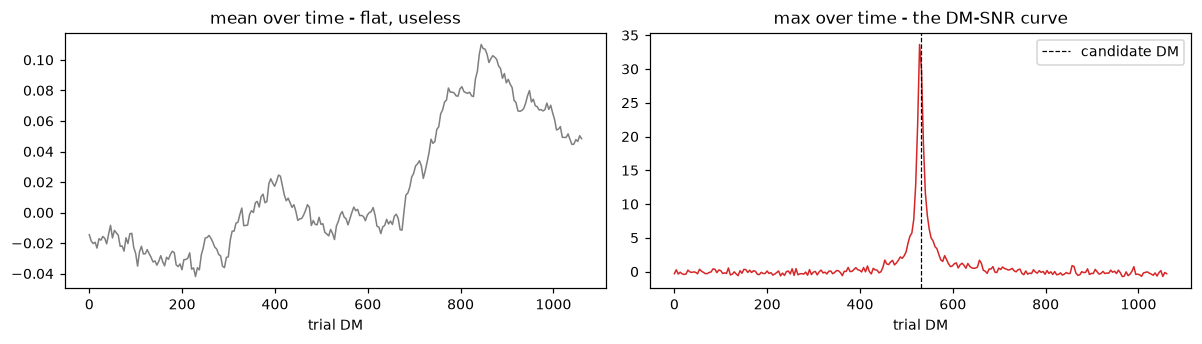

In [6]:
with h5py.File(ref.h5_path, "r") as f:
    ft_ref = f["data_freq_time"][:]
    dt_ref = f["data_dm_time"][:]

dm_ax = dm_axis(ref.dm_csv)
mean_collapse = dt_ref.mean(axis=1) - np.median(dt_ref.mean(axis=1))
max_collapse  = dm_snr_curve(dt_ref)

print(f"data_dm_time collapsed over time, candidate DM {ref.dm_csv:.2f}")
print(f"  mean : ptp {np.ptp(mean_collapse):8.4f}   peak at DM {dm_ax[mean_collapse.argmax()]:8.2f}")
print(f"  max  : ptp {np.ptp(max_collapse):8.4f}   peak at DM {dm_ax[max_collapse.argmax()]:8.2f}")
print(f"  ratio: {np.ptp(max_collapse)/np.ptp(mean_collapse):.0f}x")

# And the wrong-axis version, which also fails silently.
wrong = dt_ref.max(axis=0)
print(f"\n  wrong axis (max over DM) -> length {len(wrong)}, that's a time series, not a DM curve")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
ax[0].plot(dm_ax, mean_collapse, lw=1, color="tab:grey")
ax[0].set_title("mean over time - flat, useless"); ax[0].set_xlabel("trial DM")
ax[1].plot(dm_ax, max_collapse, lw=1, color="tab:red")
ax[1].axvline(ref.dm_csv, ls="--", lw=.8, color="k", label="candidate DM")
ax[1].set_title("max over time - the DM-SNR curve"); ax[1].set_xlabel("trial DM"); ax[1].legend()
plt.tight_layout(); plt.savefig(NB02_DIR / "collapse_convention.png", bbox_inches="tight"); plt.show()

## Per-candidate panels

### Why?
Four views of the same candidate on calibrated axes is the quickest way I've found to catch a wrong assumption. They catch orientation mistakes (a transposed array, an upside-down band) and a DM axis that isn't centred on the candidate. They can't catch a time axis with the wrong scale, since any model centred on `tcand` puts the pulse in the middle; that test is nb03 §5.

### The four panels
| panel | meaning |
|---|---|
| `data_freq_time` | dedispersed waterfall. Correct dedispersion makes the pulse vertical at t = 0 |
| `data_dm_time` | the bowtie. Should pinch at (t = 0, DM = candidate) |
| integrated profile | frequency-collapsed, one of the two curves group A uses |
| DM-SNR curve | time-collapsed with `max`, the other one |

### Orientation 
`data_freq_time` is `['time', 'frequency']` so it needs a transpose before `imshow` to get frequency on the vertical. And `foff` is negative, meaning index 0 is the top of the
band, so it wants `origin='upper'` rather than `'lower'`. `data_dm_time` is already dm-major with row 0 = DM 0, so that one takes `origin='lower'` and no transpose.

Either backwards gives you a plausible upside down picture. The red guide lines help catch that.

### Selection
Seven candidates rather than 102 are the extremes of the parameter space plus the loudest negatives. I ask for nine and dedupe on filename, and it collapses to seven because two pairs turn out to be the same object: the widest injection is the one FETCH rejected, which is the point of the last section, and the loudest negative is also the one with the most cluster members.

rendering 7 panels



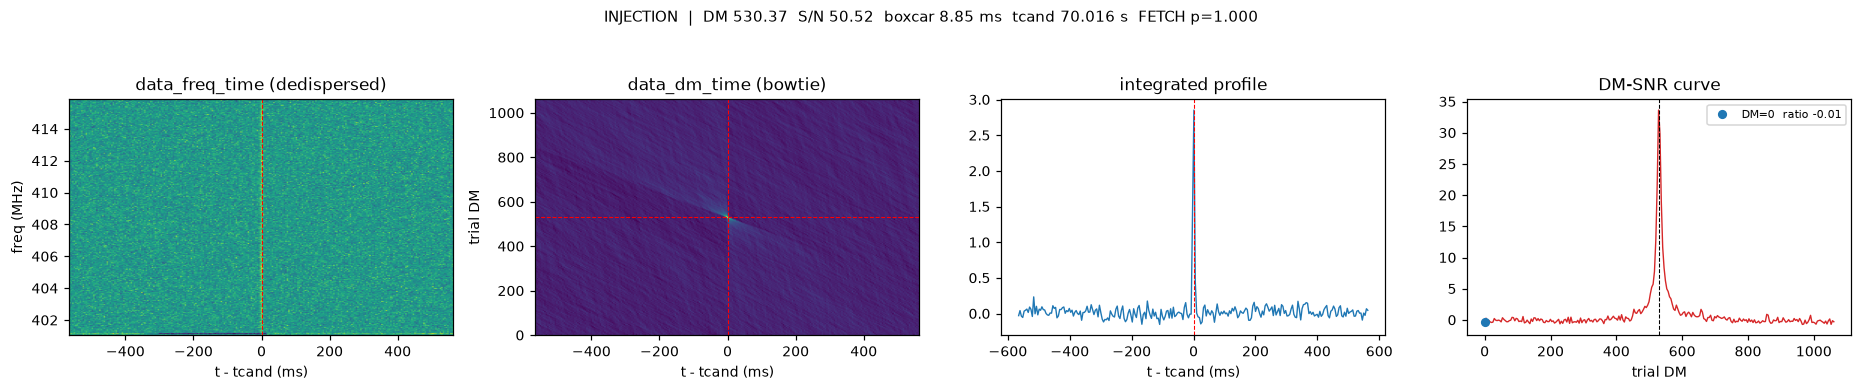

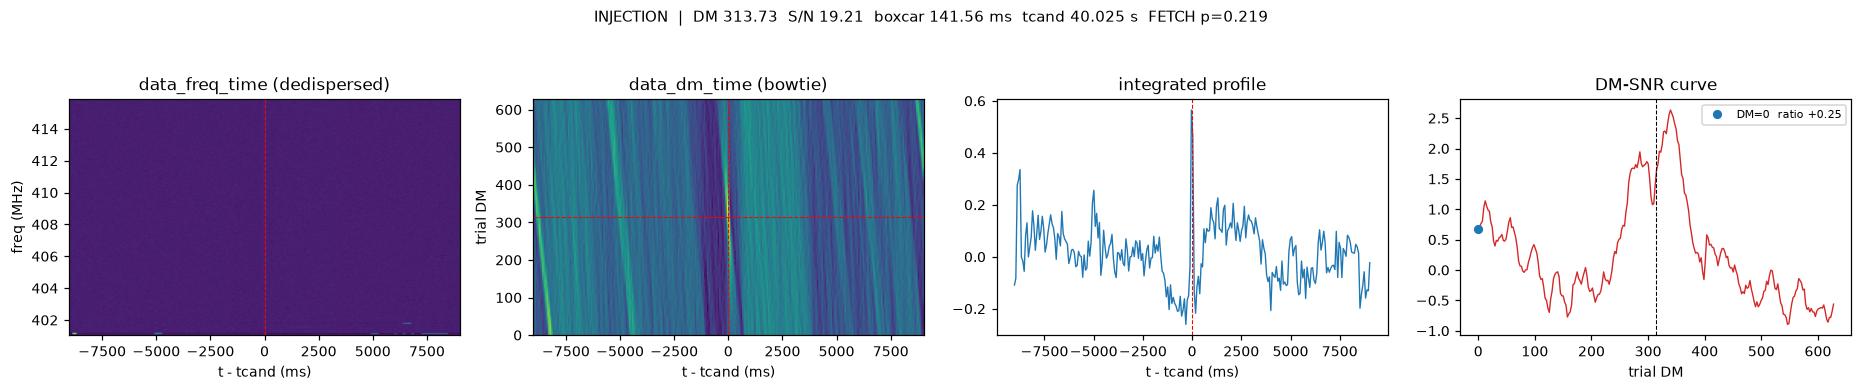

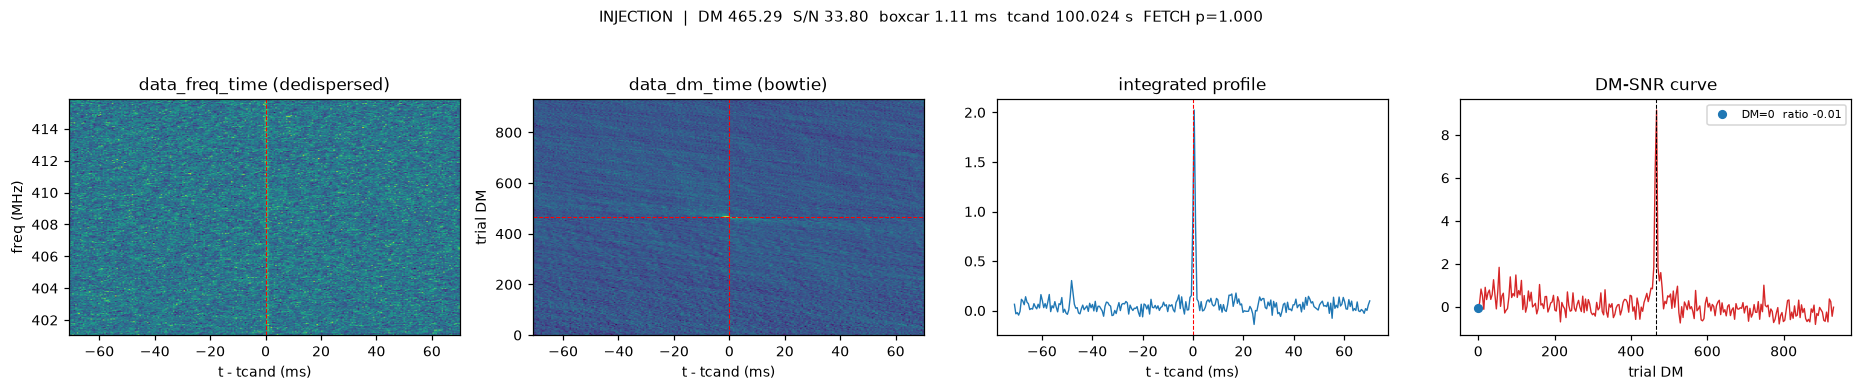

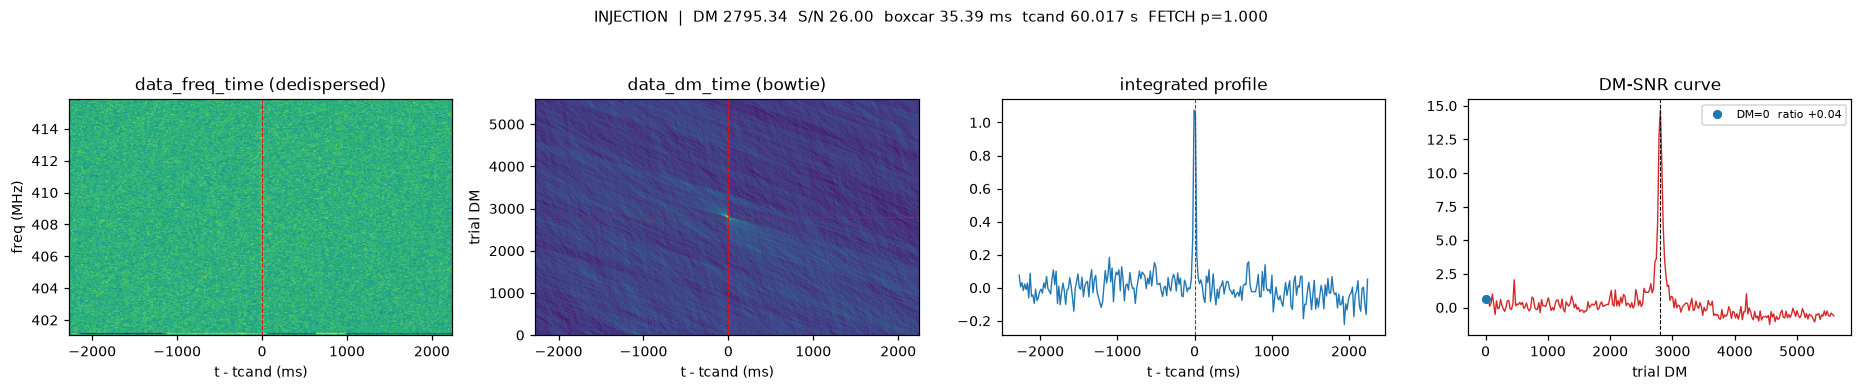

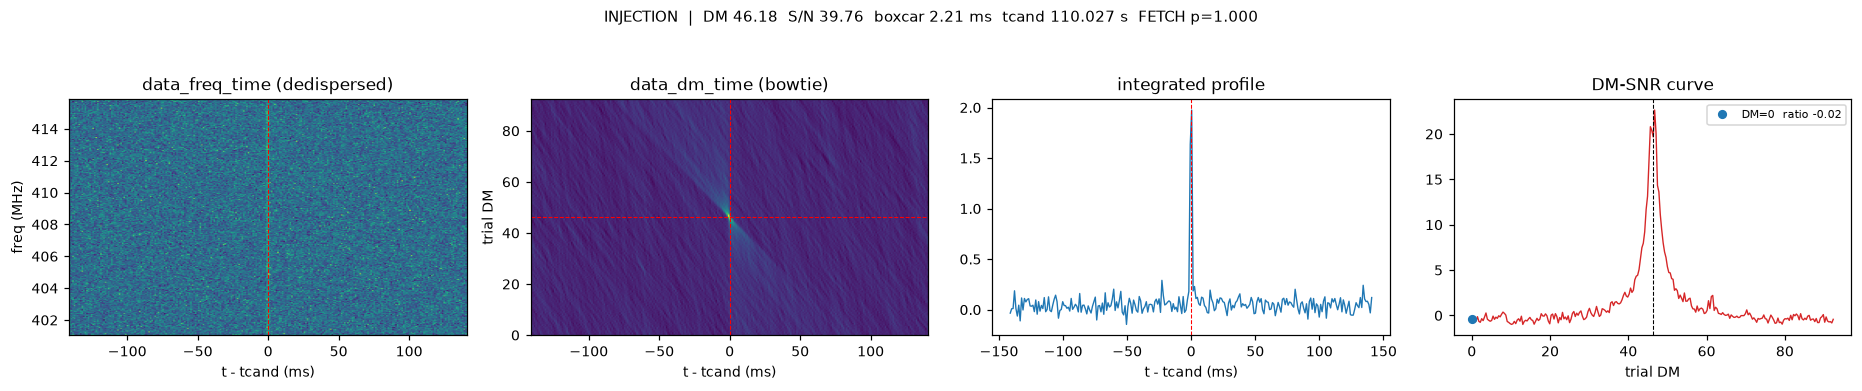

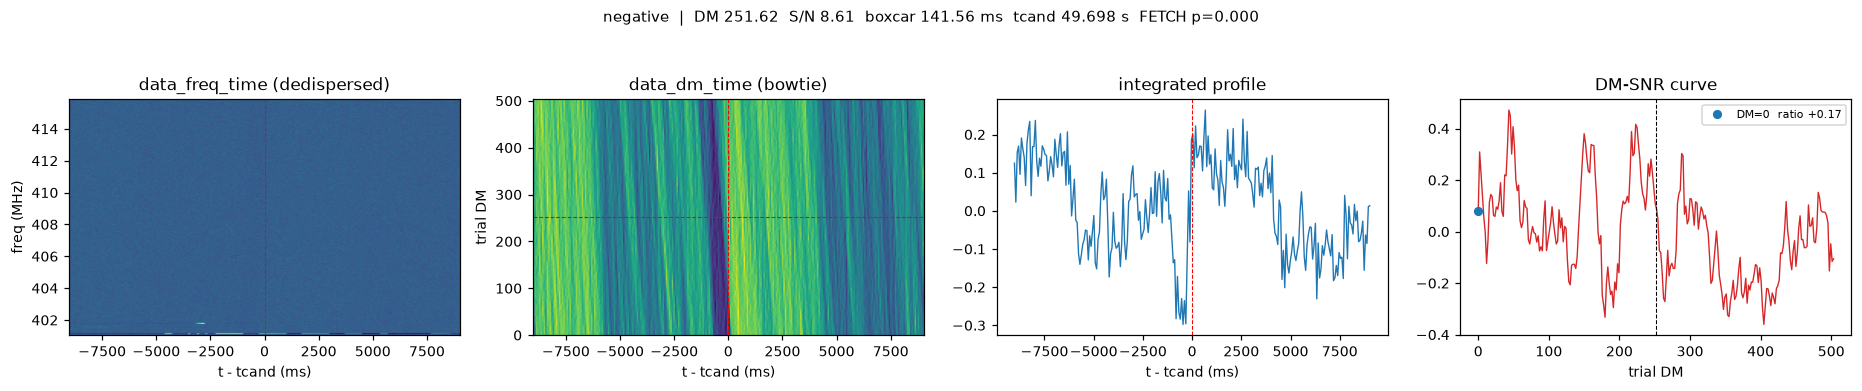

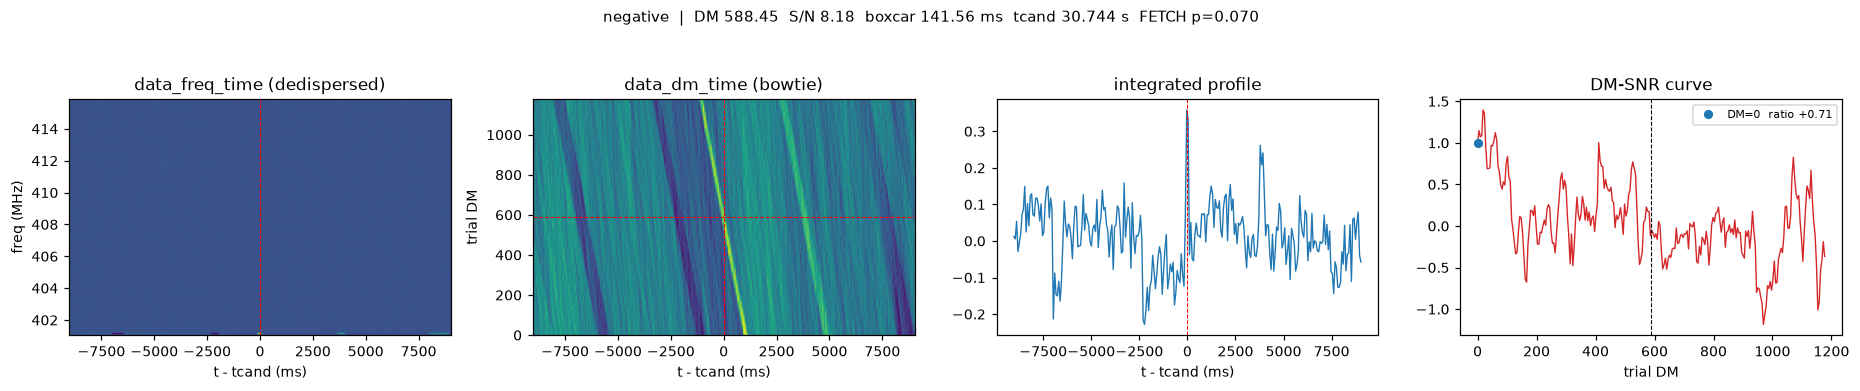

In [7]:
def panel(row, save=None):
    """Four calibrated views of one candidate."""
    with h5py.File(row.h5_path, "r") as f:
        ft = f["data_freq_time"][:]
        dt = f["data_dm_time"][:]

    t_ms = time_axis_ms(row)
    t0, t1 = t_ms[0], t_ms[-1]
    d_ax = dm_axis(row.dm_csv)
    prof, curve = integrated_profile(ft), dm_snr_curve(dt)

    tag = "INJECTION" if row.is_injection else "negative"
    fig, ax = plt.subplots(1, 4, figsize=(17, 3.3))
    fig.suptitle(f"{tag}  |  DM {row.dm_csv:.2f}  S/N {row.snr_csv:.2f}  "
                 f"boxcar {row.boxcar_ms:.2f} ms  tcand {row.tcand:.3f} s  "
                 f"FETCH p={row.fetch_prob:.3f}", y=1.06, fontsize=10)

    # freq_time: transpose (dims are time,frequency) and origin='upper' (band descends)
    ax[0].imshow(ft.T, aspect="auto", origin="upper", extent=[t0, t1, F_LO, F_HI],
                 cmap="viridis")
    ax[0].axvline(0, color="r", ls="--", lw=.7)
    ax[0].set_xlabel("t - tcand (ms)"); ax[0].set_ylabel("freq (MHz)")
    ax[0].set_title("data_freq_time (dedispersed)")

    # dm_time: no transpose, origin='lower', row 0 = DM 0
    ax[1].imshow(dt, aspect="auto", origin="lower", extent=[t0, t1, 0, 2 * row.dm_csv],
                 cmap="viridis")
    ax[1].axhline(row.dm_csv, color="r", ls="--", lw=.7)
    ax[1].axvline(0, color="r", ls="--", lw=.7)
    ax[1].set_xlabel("t - tcand (ms)"); ax[1].set_ylabel("trial DM")
    ax[1].set_title("data_dm_time (bowtie)")

    ax[2].plot(t_ms, prof, lw=.9)
    ax[2].axvline(0, color="r", ls="--", lw=.7)
    ax[2].set_xlabel("t - tcand (ms)"); ax[2].set_title("integrated profile")

    ax[3].plot(d_ax, curve, lw=.9, color="tab:red")
    ax[3].axvline(row.dm_csv, color="k", ls="--", lw=.7)
    ax[3].plot(0, curve[0], "o", ms=5, color="tab:blue", label=f"DM=0  ratio {curve[0]/curve.max():+.2f}")
    ax[3].set_xlabel("trial DM"); ax[3].set_title("DM-SNR curve"); ax[3].legend(fontsize=7)

    plt.tight_layout()
    if save:
        plt.savefig(save, bbox_inches="tight")
    plt.show()


inj = cands[cands["is_injection"]]
neg = cands[~cands["is_injection"]]
picks = pd.concat([
    inj.nlargest(1, "snr_csv"),          # loudest
    inj[inj["fetch_prob"] < 0.5],        # the one FETCH rejected
    inj.nlargest(1, "boxcar_ms"),        # widest
    inj.nsmallest(1, "boxcar_ms"),       # narrowest
    inj.nlargest(1, "dm_csv"),           # highest DM
    inj.nsmallest(1, "dm_csv"),          # lowest DM
    neg.nlargest(2, "snr_csv"),          # loudest RFI
    neg.nlargest(1, "members"),
]).drop_duplicates(subset="h5_name")

print(f"rendering {len(picks)} panels\n")
for i, (_, r) in enumerate(picks.iterrows()):
    panel(r, save=NB02_DIR / f"panel_{i:02d}_{'inj' if r.is_injection else 'neg'}.png")

## Overlaying the dispersion track

### Why
The panels show the pulse is vertical, which tells us the dedispersion worked. This cell asks: **is it vertical at the right scale?**

`data_freq_time` has already been dedispersed at the candidate DM, so a correct pipeline plus a correct time axis should put the pulse on a vertical line at t = 0. Overlaying the tracks the pulse would have followed if the DM were wrong by +/-5% and +/-10% turns the plot into a rough ruler:

    residual delay at frequency f, for a DM error dDM
        dt(f) = 4148808 * dDM * (1/f^2 - 1/f_hi^2) / 1000     seconds

Reference is the top of the band because that's where `your` dedisperses to, which is also why those curves all pin at t = 0 up at the top and fan out downwards.

### Reading it
If the time axis were mis-scaled by some factor the real pulse would still be vertical as dedispersion doesn't care what we've decided to call the axis, but the +/-10% tracks would be the wrong width for the frame. It's a ruler for the eye, not a measurement. The measurement is nb03 §5. The cell prints the size of the 10% track against the window for each candidate it draws, so the ruler can be read off.

### Guards
Injections only. Overlaying a dispersion track on a noise candidate draws a lovely curve through absolutely nothing.

DM   530.37: a 10% DM error spreads the pulse over    95.6 ms of a  1128.0 ms window (8%)


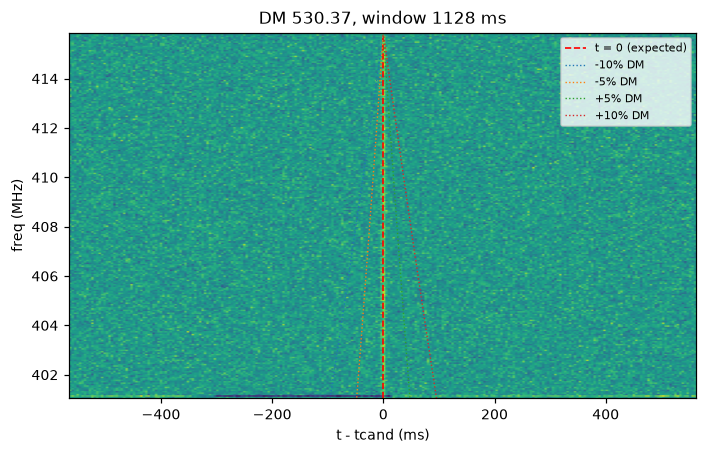

DM  2795.34: a 10% DM error spreads the pulse over   504.1 ms of a  4512.2 ms window (11%)


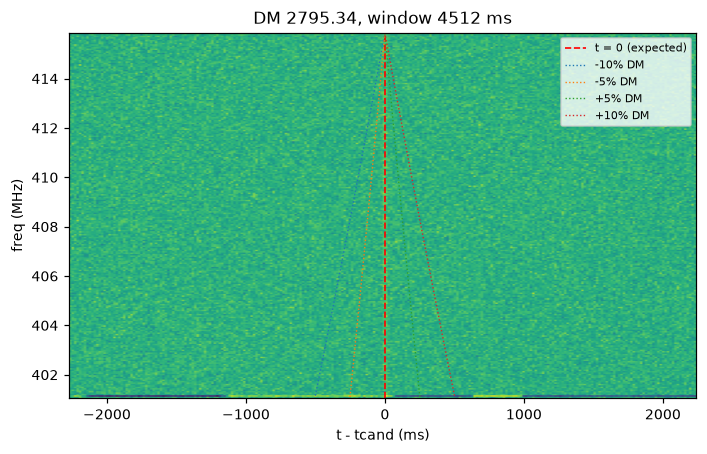

In [8]:
def dispersion_overlay(row, dm_errors=(-0.10, -0.05, 0.05, 0.10), save=None):
    with h5py.File(row.h5_path, "r") as f:
        ft = f["data_freq_time"][:]

    t_ms = time_axis_ms(row)
    freqs = freq_axis()

    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    ax.imshow(ft.T, aspect="auto", origin="upper",
              extent=[t_ms[0], t_ms[-1], F_LO, F_HI], cmap="viridis")
    ax.axvline(0, color="r", ls="--", lw=1.1, label="t = 0 (expected)")

    for e in dm_errors:
        # residual delay referenced to the top of the band, ms
        dt = 4148808.0 * (e * row.dm_csv) * (1 / freqs**2 - 1 / F_HI**2) / 1000.0 * 1e3
        ax.plot(dt, freqs, lw=.9, ls=":", label=f"{e:+.0%} DM")

    ax.set_xlim(t_ms[0], t_ms[-1])
    ax.set_xlabel("t - tcand (ms)"); ax.set_ylabel("freq (MHz)")
    ax.set_title(f"DM {row.dm_csv:.2f}, window {np.ptp(t_ms):.0f} ms")
    track10 = 4148808.0 * (0.10 * row.dm_csv) * (1 / F_LO**2 - 1 / F_HI**2) / 1000.0 * 1e3
    print(f"DM {row.dm_csv:8.2f}: a 10% DM error spreads the pulse over {track10:7.1f} ms "
          f"of a {np.ptp(t_ms):7.1f} ms window ({track10 / np.ptp(t_ms):.0%})")
    ax.legend(fontsize=7, loc="upper right")
    plt.tight_layout()
    if save:
        plt.savefig(save, bbox_inches="tight")
    plt.show()


for _, r in pd.concat([inj.nlargest(1, "snr_csv"), inj.nlargest(1, "dm_csv")]).iterrows():
    dispersion_overlay(r, save=NB02_DIR / f"overlay_dm{r.dm_csv:.0f}.png")

## The `std == 1` problem

### Why?
nb01 worked out that candmaker normalises both images to std exactly 1.0 and concluded the 8 features have to come off 1-D collapsed curves. That was an assertion, so this cell is the evidence.

### Measurement
Compute mean / std / skewness / excess kurtosis two ways for all 102 candidates, once on the flattened 2-D `data_freq_time`, once on the 1-D integrated profile then compare the spread across candidates. A feature with no spread carries no information regardless of its value.

### What comes out
`std` on the image is **1.0 for every one of the 102**, to within float32 rounding and the whole spread is 2.2e-07, which is the last couple of bits of a float32 and not a range in any useful sense. (the values aren't bit-identical, so `nunique()` will
happily report 102 by rounding) 

Against that, collapsing to the profile gives `std` a genuine range of [0.060, 0.936], a spread of 0.88 which is about six orders of magnitude more. So on the image `std` is a constant.

But `mean` comes out identical either way... same value, same range, every digit. Collapsing by `mean` preserves the grand mean by construction, so averaging over frequency can't manufacture information the image didn't have. candmaker's `normalise` subtracts the image **median** and divides by the std, so the image mean is `(mean - median) / std` of the image before normalising. That's a pixel-skewness number set mostly by how many raw samples each pixel sums, not a brightness, and the profile mean inherits it.

So collapsing rescues three of the four stats:

| stat | rescued? |
|---|---|
| mean | **no**: identical by construction, a normalisation artefact |
| std | yes: zero variance becomes a real range |
| skewness | yes |
| excess kurtosis | yes |

spread ACROSS the 102 candidates - 2-D image vs 1-D integrated profile

stat      image std                image range  profile std              profile range
mean       0.117576          [-0.4330, 0.1540]     0.117577          [-0.4330, 0.1540]
std        0.000000           [1.0000, 1.0000]     0.186649           [0.0598, 0.9364]
skew       5.807961         [-1.4304, 18.2131]     2.478897         [-2.1182, 10.6560]
kurt     377.015659        [0.1154, 1345.5595]    26.560316        [-1.8973, 132.4850]

  image std: min 0.999999904  max 1.000000126  spread 2.22e-07  (float32 rounding, not a real range)
  profile std spread for comparison: 0.8766
  mean identical either way: max |diff| = 5.04e-08


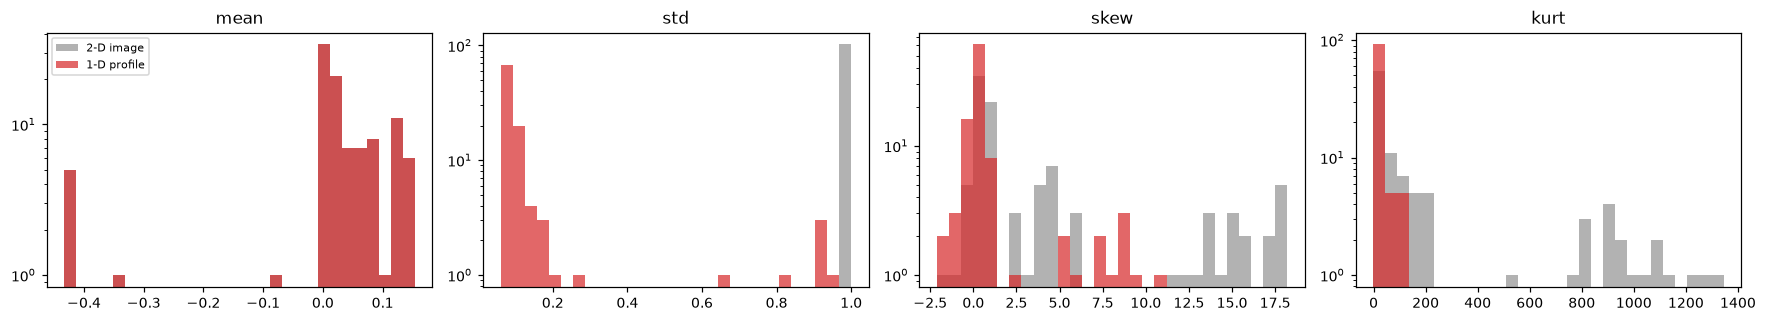

In [9]:
def four_stats(x):
    x = np.asarray(x, dtype=float).ravel()
    return dict(mean=x.mean(), std=x.std(),
                skew=skew(x), kurt=kurtosis(x))   # kurtosis() is excess by default


srows = []
for _, r in cands.iterrows():
    with h5py.File(r.h5_path, "r") as f:
        ft = f["data_freq_time"][:]
        dt = f["data_dm_time"][:]
    img = four_stats(ft)
    prf = four_stats(integrated_profile(ft))
    dmc = four_stats(dm_snr_curve(dt))
    srows.append({"h5_name": r.h5_name, "is_injection": r.is_injection,
                  **{f"img_{k}": v for k, v in img.items()},
                  **{f"prof_{k}": v for k, v in prf.items()},
                  **{f"dmc_{k}": v for k, v in dmc.items()}})

stats = pd.DataFrame(srows)

print("spread ACROSS the 102 candidates - 2-D image vs 1-D integrated profile\n")
print(f"{'stat':<6} {'image std':>12} {'image range':>26} {'profile std':>12} {'profile range':>26}")
for k in ["mean", "std", "skew", "kurt"]:
    a, b = stats[f"img_{k}"], stats[f"prof_{k}"]
    print(f"{k:<6} {a.std():12.6f} {f'[{a.min():.4f}, {a.max():.4f}]':>26} "
          f"{b.std():12.6f} {f'[{b.min():.4f}, {b.max():.4f}]':>26}")

print(f"\n  image std: min {stats['img_std'].min():.9f}  max {stats['img_std'].max():.9f}  "
      f"spread {np.ptp(stats['img_std']):.2e}  (float32 rounding, not a real range)")
print(f"  profile std spread for comparison: {np.ptp(stats['prof_std']):.4f}")
print(f"  mean identical either way: max |diff| = "
      f"{(stats['img_mean'] - stats['prof_mean']).abs().max():.2e}")

fig, ax = plt.subplots(1, 4, figsize=(16, 3.0))
for i, k in enumerate(["mean", "std", "skew", "kurt"]):
    a, b = stats[f"img_{k}"], stats[f"prof_{k}"]
    rng = np.r_[a.values, b.values]
    bins = np.linspace(np.nanmin(rng), np.nanmax(rng), 30)
    ax[i].hist(a, bins=bins, alpha=.6, label="2-D image", color="tab:grey")
    ax[i].hist(b, bins=bins, alpha=.7, label="1-D profile", color="tab:red")
    ax[i].set_title(k); ax[i].set_yscale("log")
    if i == 0:
        ax[i].legend(fontsize=7)
plt.tight_layout(); plt.savefig(NB02_DIR / "std_collapse.png", bbox_inches="tight"); plt.show()

## Positives against negatives

### The FETCH failure
nb01 pinned this: TOA 40.008 s, DM 313.734, S/N 19.21, `members` 9302, FETCH probability **0.219**. Heimdall found it without any trouble. FETCH threw it out.

It's the widest injection at 125.8 ms injected FWHM, 2.4x the next widest, and needs 88.9% of the boxcar ceiling against 37.0% for the widest one FETCH accepted. So it looks like a classifier failure at the wide end of the parameter space rather than a search failure. (The printout below compares Heimdall boxcars instead, 1024 against 512 samples, which is why it says 2.00x.)

Worth watching the DM-SNR curve in its panel. That's the discriminator FETCH doesn't have.

### Third panel left.

Eyeballing the leftmost panel you see flat noise, and most of that is my colour scale rather than the data. `imshow` with no `vmin`/`vmax` stretches the map over the full range, and here that range is set by band-edge RFI channels far out in the tail. The burst is spread over about 2 columns x 256 sub-bands, about 500 pixels, so at S/N 19.2 each pixel holds roughly 19.2 / sqrt(500) ~ 0.9 sigma, a sliver of that colour range. The panels where you can see the stripe are the ones without a hot channel setting the scale.

The rescaled grid below fixes the scale: mask the hot channels, clip at 1-99 pct, and the vertical line shows up in all four. The image does get Heimdall's integration, since candmaker sums 512 raw samples into each column for this boxcar-1024 candidate. What it can't show is the width: 125.8 ms of pulse and 70.8 ms of pulse both come out as two columns.

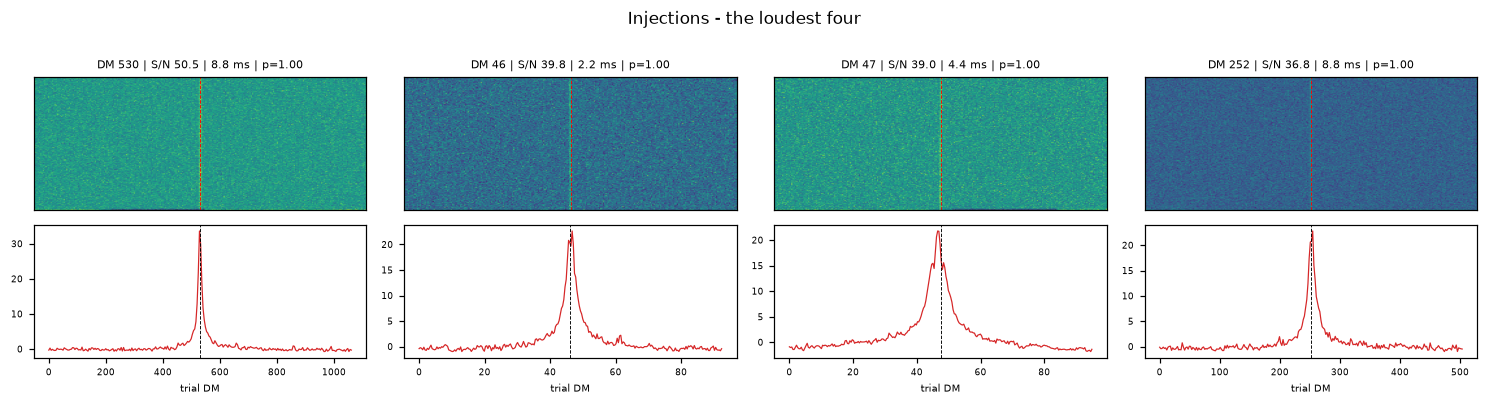

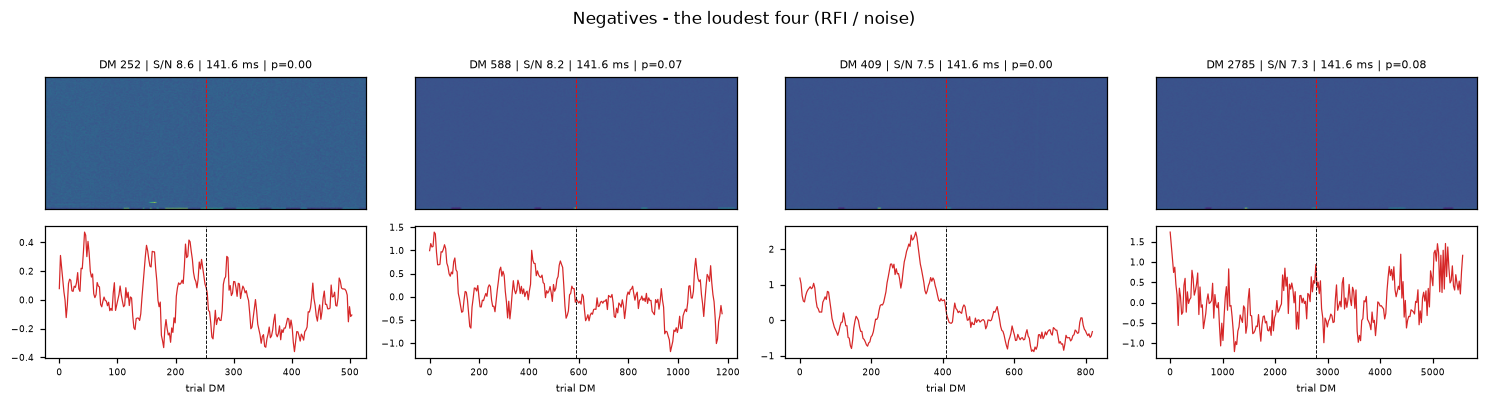

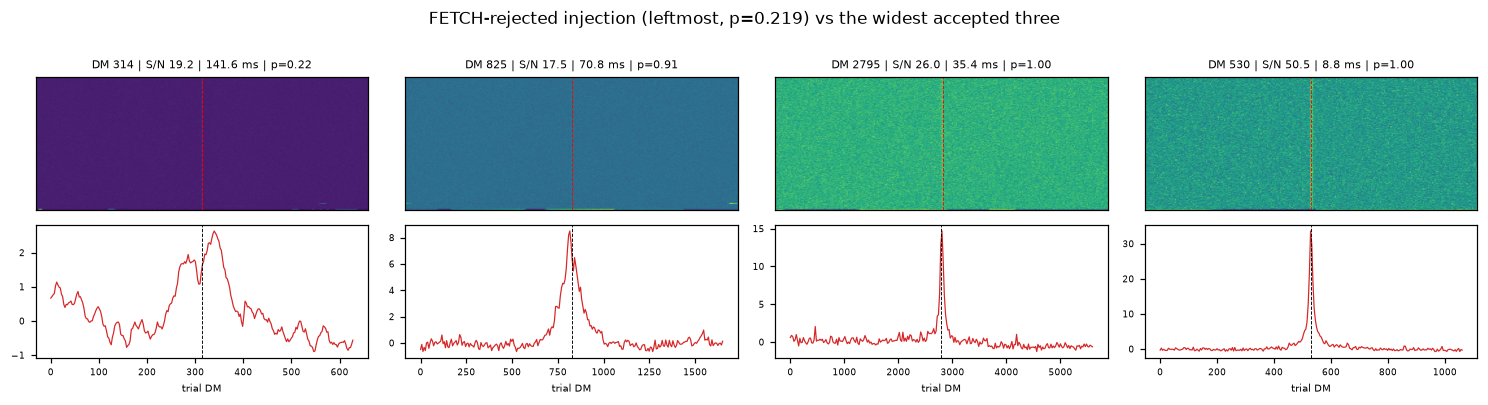

rejected: DM 313.734, S/N 19.21, width 141.56 ms, FETCH p=0.219
widest accepted: 70.78 ms (ratio 2.00x)


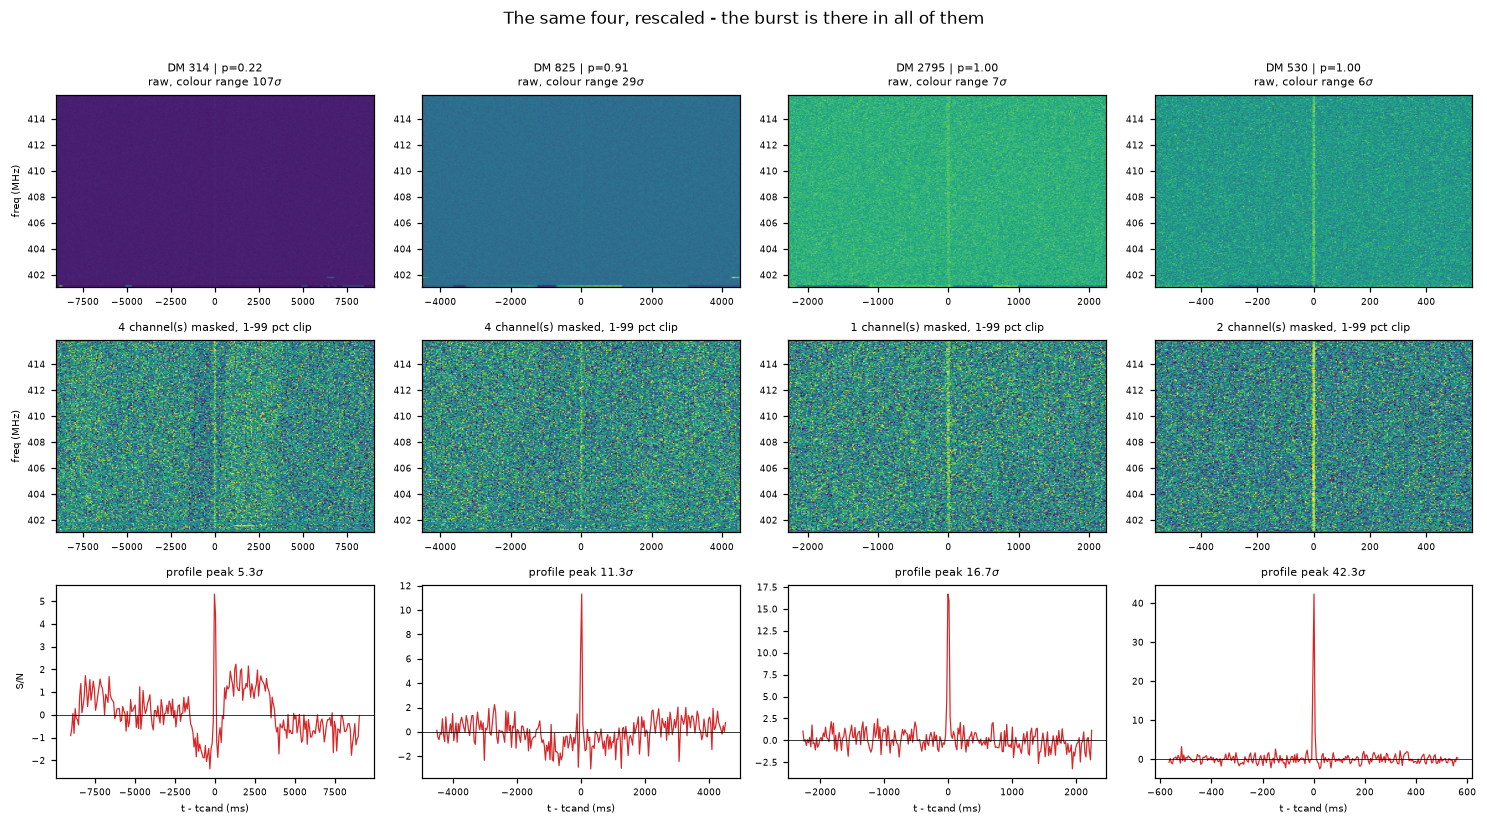

In [10]:
def grid(rows, title, ncol=4, save=None):
    """Compact freq_time + DM-SNR curve pairs, calibrated axes."""
    rows = list(rows)
    nrow = int(np.ceil(len(rows) / ncol))
    fig, axes_ = plt.subplots(nrow * 2, ncol, figsize=(3.4 * ncol, 3.6 * nrow),
                              squeeze=False)
    fig.suptitle(title, y=1.005, fontsize=11)

    for j, r in enumerate(rows):
        ri, ci = divmod(j, ncol)
        a_img, a_crv = axes_[ri * 2][ci], axes_[ri * 2 + 1][ci]
        with h5py.File(r.h5_path, "r") as f:
            ft, dt = f["data_freq_time"][:], f["data_dm_time"][:]
        t_ms = time_axis_ms(r)
        curve = dm_snr_curve(dt)

        a_img.imshow(ft.T, aspect="auto", origin="upper",
                     extent=[t_ms[0], t_ms[-1], F_LO, F_HI], cmap="viridis")
        a_img.axvline(0, color="r", ls="--", lw=.6)
        a_img.set_title(f"DM {r.dm_csv:.0f} | S/N {r.snr_csv:.1f} | "
                        f"{r.boxcar_ms:.1f} ms | p={r.fetch_prob:.2f}", fontsize=7.5)
        a_img.set_xticks([]); a_img.set_yticks([])

        a_crv.plot(dm_axis(r.dm_csv), curve, lw=.8, color="tab:red")
        a_crv.axvline(r.dm_csv, color="k", ls="--", lw=.6)
        a_crv.tick_params(labelsize=6); a_crv.set_xlabel("trial DM", fontsize=6.5)

    for j in range(len(rows), nrow * ncol):
        ri, ci = divmod(j, ncol)
        axes_[ri * 2][ci].axis("off"); axes_[ri * 2 + 1][ci].axis("off")

    plt.tight_layout()
    if save:
        plt.savefig(save, bbox_inches="tight")
    plt.show()


grid([r for _, r in inj.nlargest(4, "snr_csv").iterrows()],
     "Injections - the loudest four", save=NB02_DIR / "grid_positives.png")

grid([r for _, r in neg.nlargest(4, "snr_csv").iterrows()],
     "Negatives - the loudest four (RFI / noise)", save=NB02_DIR / "grid_negatives.png")

# The rejected injection, against the three accepted ones nearest it in width.
rej = inj[inj["fetch_prob"] < 0.5]
acc = inj[inj["fetch_prob"] >= 0.5].nlargest(3, "boxcar_ms")
grid([r for _, r in pd.concat([rej, acc]).iterrows()],
     "FETCH-rejected injection (leftmost, p=0.219) vs the widest accepted three",
     save=NB02_DIR / "grid_fetch_failure.png")

print(f"rejected: DM {rej.iloc[0].dm_csv:.3f}, S/N {rej.iloc[0].snr_csv:.2f}, "
      f"width {rej.iloc[0].boxcar_ms:.2f} ms, FETCH p={rej.iloc[0].fetch_prob:.3f}")
print(f"widest accepted: {acc.iloc[0].boxcar_ms:.2f} ms "
      f"(ratio {rej.iloc[0].boxcar_ms / acc.iloc[0].boxcar_ms:.2f}x)")

def robust_z(a):
    """Median-and-MAD z-score. MAD is the right scale here - the outliers we
    are hunting would inflate a std-based one."""
    med = np.median(a)
    return (a - med) / (np.median(np.abs(a - med)) * 1.4826)


def mask_hot_channels(ft, pixel_sigma=10.0, band_sigma=5.0):
    """Blank channels that carry a >`pixel_sigma` pixel, or whose own median
    sits >`band_sigma` off the band. Catches RFI spikes and hot channels both.
    """
    z = robust_z(ft)
    hot = set(np.argwhere(z > pixel_sigma)[:, 1].tolist())
    hot |= set(np.flatnonzero(np.abs(robust_z(np.median(ft, axis=0))) > band_sigma).tolist())
    hot = np.array(sorted(hot), dtype=int)
    out = ft.copy()
    if hot.size:
        out[:, hot] = np.median(ft)
    return out, hot


def grid_rescaled(rows, title, save=None):
    """Raw imshow / masked and clipped / freq-averaged profile, one column each.

    Same panels as grid(), but showing what the default colour scale hides.
    """
    rows = list(rows)
    ncol = len(rows)
    fig, ax = plt.subplots(3, ncol, figsize=(3.4 * ncol, 7.4), squeeze=False)
    fig.suptitle(title, y=1.005, fontsize=11)

    for j, r in enumerate(rows):
        with h5py.File(r.h5_path, "r") as f:
            ft = f["data_freq_time"][:]
        t_ms = time_axis_ms(r)
        ext = [t_ms[0], t_ms[-1], F_LO, F_HI]

        clean, hot = mask_hot_channels(ft)
        lo, hi = np.percentile(clean, [1, 99])
        prof = robust_z(clean.mean(axis=1))

        ax[0][j].imshow(ft.T, aspect="auto", origin="upper", extent=ext, cmap="viridis")
        ax[0][j].set_title(f"DM {r.dm_csv:.0f} | p={r.fetch_prob:.2f}\n"
                           f"raw, colour range {robust_z(ft).max():.0f}$\\sigma$",
                           fontsize=7.5)

        ax[1][j].imshow(clean.T, aspect="auto", origin="upper", extent=ext,
                        cmap="viridis", vmin=lo, vmax=hi)
        ax[1][j].set_title(f"{len(hot)} channel(s) masked, 1-99 pct clip", fontsize=7.5)

        ax[2][j].plot(t_ms, prof, lw=.8, color="tab:red")
        ax[2][j].axhline(0, color="k", lw=.5)
        ax[2][j].set_title(f"profile peak {prof.max():.1f}$\\sigma$", fontsize=7.5)
        ax[2][j].set_xlabel("t - tcand (ms)", fontsize=6.5)
        for a in ax[:, j]:
            a.tick_params(labelsize=6)

    for i, lab in enumerate(["freq (MHz)", "freq (MHz)", "S/N"]):
        ax[i][0].set_ylabel(lab, fontsize=6.5)

    plt.tight_layout()
    if save:
        plt.savefig(save, bbox_inches="tight")
    plt.show()


grid_rescaled([r for _, r in pd.concat([rej, acc]).iterrows()],
              "The same four, rescaled - the burst is there in all of them",
              save=NB02_DIR / "grid_fetch_failure_rescaled.png")

## Nb02 Handover

### Why?
nb03 and nb04 both need the axis calibration. `dm_step` depends on DM and `h5_t_step_ms` on the boxcar, so they have to travel as a per-candidate table.

### The files
| file | meaning |
|---|---|
| `nb02_axis_calibration.csv` | 102 rows. Per-candidate `time_decim`, `h5_t_step_ms`, `h5_window_ms`, `h5_t0_ms`, `tcand_col` (the fractional column `tcand` falls in), `dm_step`, the raw window half-width nb03 cuts (`raw_half_window_ms`), the peak offsets from the image centre and from `tcand`, and `dm0_ratio` |
| `nb02_curve_stats.csv` | the 2-D vs 1-D stats comparison behind the `std == 1` result, keyed by `h5_name` |
| `nb02_summary.json` | the findings in machine-readable form |
| PNGs | panels, grids, overlays, histograms |

### For nb03
The scale of both axes still needs a test against the raw data, and nb03 §5 does it by rebuilding the h5 profile and DM rows from raw counts.

### For nb04
Three things carry over. `dm0_ratio` is a feature that's already computed, so it comes free. A column is `time_decim * tsamp`, so anything measured in columns is in units of the boxcar, and converting it to ms multiplies in `boxcar_samples`. And the two `mean` features are `(mean - median) / std` of the image, a normalisation by-product, so worth checking prior to encoding.

In [11]:
axes.to_csv(NB02_DIR / "nb02_axis_calibration.csv", index=False)
stats.to_csv(NB02_DIR / "nb02_curve_stats.csv", index=False)

summary = {
    "n_candidates": int(len(cands)),
    "n_injections": int(cands["is_injection"].sum()),
    "dm_axis": {
        "formula": "linspace(0, 2*dm, 256)",
        "source": "your/utils/gpu.py gpu_dedisp_and_dmt_crop (dm_list)",
        "dm_zero_in_image": True,
        "peak_row_expected": 127.5,
        "peak_row_injections": [int(pos.dm_peak_row.min()),
                                int(pos.dm_peak_row.median()),
                                int(pos.dm_peak_row.max())],
    },
    "time_axis": {
        "formula": "chunk from get_chunk (widened to width*128 samples), sum over "
                   "max(1, width//2) samples per column, centre 256 columns",
        "column_s": "max(1, boxcar_samples // 2) * tsamp",
        "source": "your/candidate.py Candidate.get_chunk + your/utils/gpu.py gpu_dedisp_and_dmt_crop",
        "h5_window_ms_range": [float(axes.h5_window_ms.min()), float(axes.h5_window_ms.max())],
        "profile_peak_offset_columns_median": float((pos.prof_peak_ms / pos.h5_t_step_ms).abs().median()),
    },
    "collapse_convention": {
        "integrated_profile": "data_freq_time.mean(axis=1)  # collapse frequency",
        "dm_snr_curve": "data_dm_time.max(axis=1)  # collapse time, MAX not mean",
        "mean_collapse_is_flat": True,
    },
    "dm0_ratio": {
        "auc": float(auc),
        "injection_median": float(p.median()),
        "negative_median": float(n.median()),
        "computable": True,
    },
    "std_collapse": {
        "image_std_spread": float(np.ptp(stats["img_std"])),
        "image_std_mean": float(stats["img_std"].mean()),
        "image_std_constant_to_1e6": bool(np.allclose(stats["img_std"], 1.0, atol=1e-6)),
        "profile_std_range": [float(stats["prof_std"].min()), float(stats["prof_std"].max())],
        "mean_identical_max_absdiff": float(
            (stats["img_mean"] - stats["prof_mean"]).abs().max()),
        "stats_rescued_by_collapsing": ["std", "skew", "kurt"],
        "stats_not_rescued": ["mean"],
    },
    "stale_attrs_found": ["nspectra", "dm_opt", "snr_opt"],
}

with open(NB02_DIR / "nb02_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))
print(f"\nwrote {len(list(NB02_DIR.glob('*')))} files to {NB02_DIR}")

{
  "n_candidates": 102,
  "n_injections": 13,
  "dm_axis": {
    "formula": "linspace(0, 2*dm, 256)",
    "source": "your/utils/gpu.py gpu_dedisp_and_dmt_crop (dm_list)",
    "dm_zero_in_image": true,
    "peak_row_expected": 127.5,
    "peak_row_injections": [
      125,
      128,
      138
    ]
  },
  "time_axis": {
    "formula": "chunk from get_chunk (widened to width*128 samples), sum over max(1, width//2) samples per column, centre 256 columns",
    "column_s": "max(1, boxcar_samples // 2) * tsamp",
    "source": "your/candidate.py Candidate.get_chunk + your/utils/gpu.py gpu_dedisp_and_dmt_crop",
    "h5_window_ms_range": [
      35.38944,
      18119.39328
    ],
    "profile_peak_offset_columns_median": 0.45298032407738215
  },
  "collapse_convention": {
    "integrated_profile": "data_freq_time.mean(axis=1)  # collapse frequency",
    "dm_snr_curve": "data_dm_time.max(axis=1)  # collapse time, MAX not mean",
    "mean_collapse_is_flat": true
  },
  "dm0_ratio": {
    "auc":